# Notebook 1 — Exploratory Data Analysis (R2)
Rice Variety Classification | F20DL 2026/2027

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/tabular/rice_cammeo_osmancik.csv')
X = df.drop(columns=['Class'])
y = df['Class']
df.head()

Matplotlib is building the font cache; this may take a moment.


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


## 1. Dataset Overview

In [2]:
print(df.shape)
print(df.dtypes)
df.describe()

(3810, 8)
Area                   int64
Perimeter            float64
Major_Axis_Length    float64
Minor_Axis_Length    float64
Eccentricity         float64
Convex_Area            int64
Extent               float64
Class                    str
dtype: object


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000,3810.000000
mean,12667.727559,454.239180,188.776222,86.313750,0.886871,12952.496850,0.661934
std,1732.367706,35.597081,17.448679,5.729817,0.020818,1776.972042,0.077239
min,7551.000000,359.100006,145.264465,59.532406,0.777233,7723.000000,0.497413
25%,11370.500000,426.144752,174.353855,82.731695,0.872402,11626.250000,0.598862
50%,12421.500000,448.852493,185.810059,86.434647,0.889050,12706.500000,0.645361
75%,13950.000000,483.683746,203.550438,90.143677,0.902588,14284.000000,0.726562
max,18913.000000,548.445984,239.010498,107.542450,0.948007,19099.000000,0.861050


## 2. Missing Values & Class Distribution

Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64


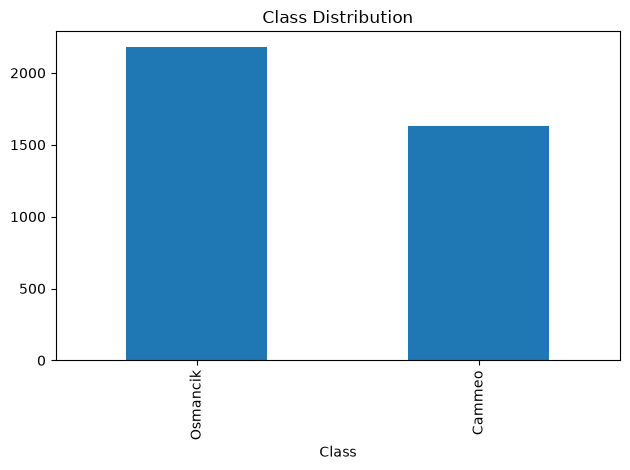

In [3]:
print(df.isnull().sum())
df['Class'].value_counts().plot(kind='bar', title='Class Distribution')
plt.tight_layout()
plt.show()

## 3. Feature Distributions

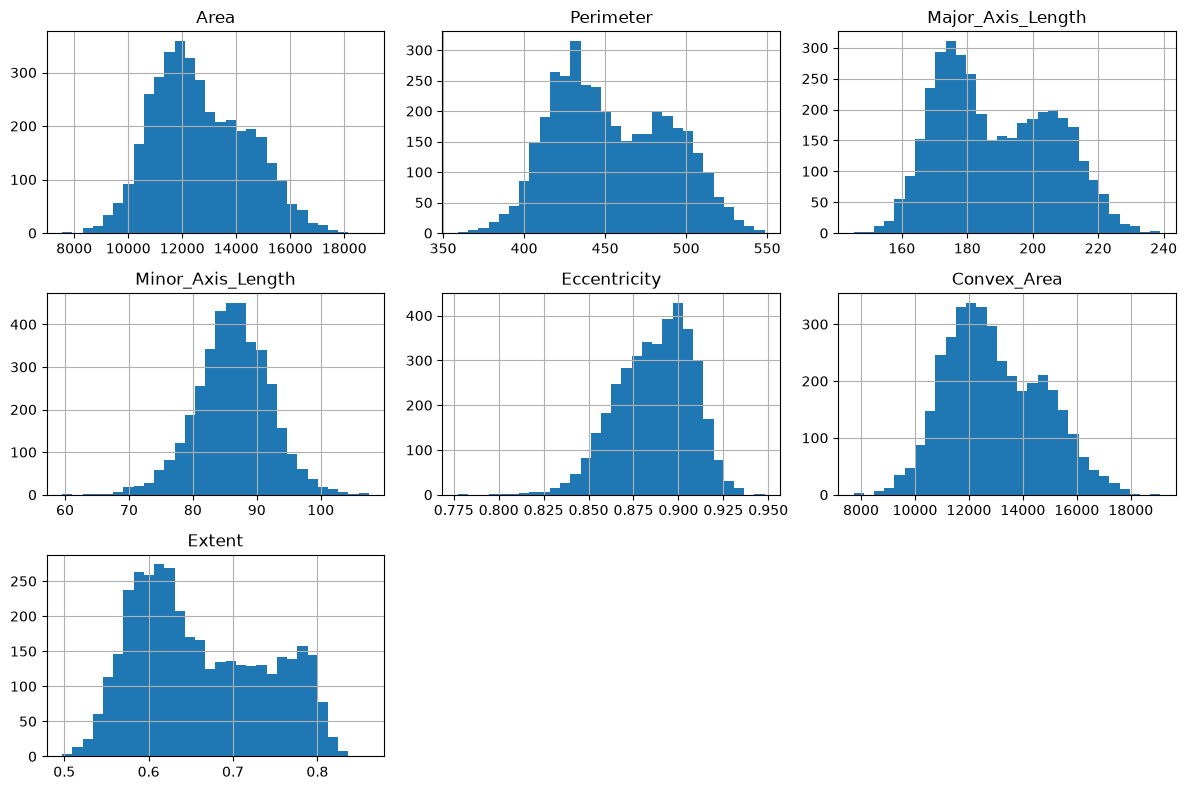

In [4]:
df.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

## 4. Correlation Heatmap

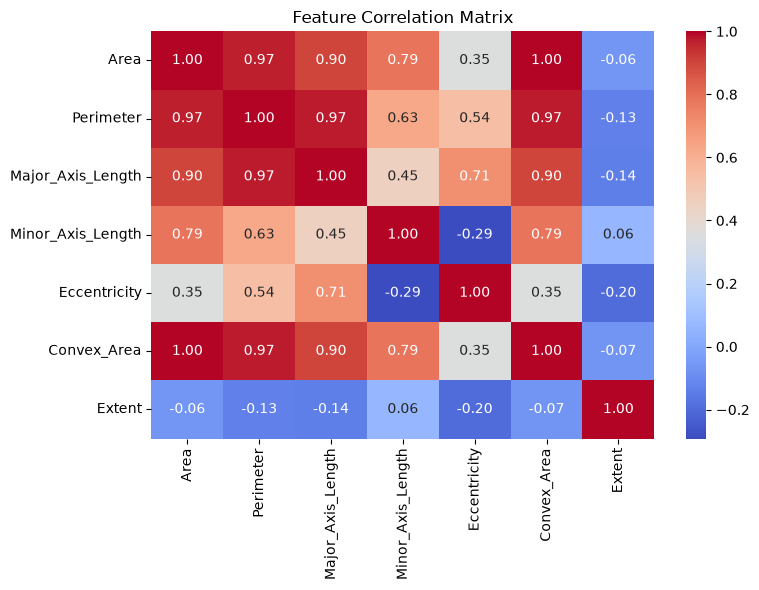

In [5]:
plt.figure(figsize=(8,6))
sns.heatmap(X.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## 5. Feature Selection via Mutual Information

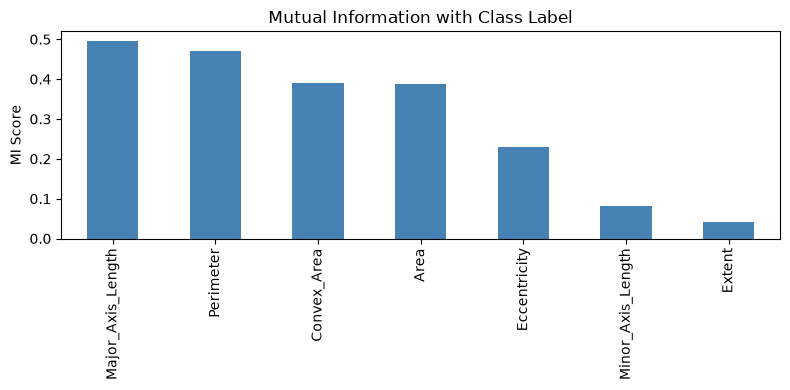

Major_Axis_Length    0.495242
Perimeter            0.470448
Convex_Area          0.390791
Area                 0.388515
Eccentricity         0.229186
Minor_Axis_Length    0.082253
Extent               0.042035
dtype: float64


In [6]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_enc = le.fit_transform(y)

mi = mutual_info_classif(X, y_enc, random_state=42)
mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
mi_series.plot(kind='bar', color='steelblue')
plt.title('Mutual Information with Class Label')
plt.ylabel('MI Score')
plt.tight_layout()
plt.savefig('../results/feature_importance.png', dpi=100)
plt.show()
print(mi_series)